# 03 — Point fit on summaries (and a second attempt, with remedies)

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

[notebook 02](02_rate.ipynb) gave a well-defined time of ordering, which answers *how fast*, not *which*
parameters produced the data.
[notebook 01](01_observables.ipynb) found a set of stationary summaries that each resolve a 10% parameter change in
one run. The natural next rung of the ladder is to **fit** all three parameters at once: find the θ whose
simulated summaries best match the observed ones.

**The rungs of the ladder here:**
- **Q1:** a point estimate from an objective function. Is the objective *noisy*, since it is computed from
  random simulations, and does that noise make the fit hard?
- **Q2:** is there *one* optimum? If different starting points lead to different answers, a single fit
  cannot be trusted.

The SIR project never showed a real optimisation difficulty; this is where we look for one, and we report
it honestly whether or not it appears.

**Data:** one observed run at the true θ* = (η, r, v₀) = (2, 1, 0.03), with N = 40, L = 10 and k = 10. The
seed is held out and never used by the fit.

**Roadmap:**

| § | question | tool |
|---|---|---|
| Definitions | what is being maximised | synthetic likelihood, CRN, criteria |
| data | how typical is the observed run? | its summaries vs the simulated distribution |
| 1 | Q1: is the objective noisy? | slices through θ*, fixed vs fresh random numbers |
| 2 | Q2: one optimum? | 8 starts, waterfall plot, optimiser paths |
| 3 | how much does the answer depend on the simulation seed? | re-fits with 4 other seeds |
| 4 | what do truth, fit and a stalled fit look like? | video |
| 5 | why do fits stall? | ℓ on the (η, r) plane |
| 6 | would restarting help? (exploratory) | restart every fit |
| 7 | what notebook 03 taught us | |
| 8–9 | a second attempt: remedies fixed in advance, and what they taught us | shrinkage, pilot, scaled steps |

The protocol was written down before any fit was run. §6 is exploratory and is
marked as such.

## Definitions

### The idea in one paragraph

We cannot write down the probability of the data given θ: the simulator is too complicated. But we can
*simulate* at any θ. The **synthetic likelihood** simulates many runs at θ, assumes their summaries are
roughly Gaussian, and asks how probable the observed summaries are under that Gaussian. If θ is right, the
observed summaries sit near the centre of the simulated cloud and the likelihood is high. If θ is wrong,
they sit far out and it is low. Maximising it over θ gives the fit. Because it comes from random
simulations, the likelihood is itself random; how much that matters is Q1's question.

**Summaries.** The vector $\mathbf{s} \in \mathbb{R}^7$ holds the per-run time averages
(defined in the [notebook 01 notebook](01_observables.ipynb) §3) of
`speed`, `cos_turn`, `corr_0_1`, `corr_1_2`, `phi`, `n_clusters`, `nn_dist`.
- **One run:** 5000 unobserved steps, then 501 frames ($k = 10$, i.e. 5000 steps), with N = 40 and L = 10.
- **The data:** $\mathbf{s}_{\rm obs}$, one run at $\theta^* = (2, 1, 0.03)$ with the held-out seed $10^6$.

**Synthetic likelihood** (Wood 2010; `flockladder.synlik.synlik`). At θ, simulate $B = 40$ independent runs
$\mathbf{s}_1..\mathbf{s}_B$ with random-number seed $\sigma$:

$$\hat\mu(\theta) = \frac1B\sum_b \mathbf{s}_b, \qquad
\hat\Sigma(\theta) = \frac{1}{B-1}\sum_b (\mathbf{s}_b-\hat\mu)(\mathbf{s}_b-\hat\mu)^\top$$

$$\ell_\sigma(\theta) = -\tfrac12\,(\mathbf{s}_{\rm obs}-\hat\mu)^\top\hat\Sigma^{-1}(\mathbf{s}_{\rm obs}-\hat\mu) - \tfrac12\log\det\hat\Sigma$$

- $\ell = -\infty$ outside the box $\eta\in[0.5,5]$, $r\in[0.5,2]$, $v_0\in[0.015,0.06]$.
- The optimisation variable is $x = \log\theta$.

**Common random numbers (CRN).** With $\sigma$ fixed for every θ, $\ell_\sigma$ is a *deterministic* function of
θ. With a fresh $\sigma$ at each θ, it is a noisy one.

**Q1, noise-to-signal.**
- $\mathrm{sd}_\sigma[\ell_\sigma(\theta^*)]$ is the spread over 8 fresh seeds.
- The signal is the drop of $\ell$ for a 10% change of one parameter $q$. It comes from a quadratic fit
  $\ell \approx a + b\,u + c\,u^2$ to the CRN slice in $u = \log(q/q^*)$ (7 points over ±30%), evaluated as
  $\Delta_{10\%} = -c\,(0.1)^2$.

$$\mathrm{NSR}_q = \frac{\mathrm{sd}_\sigma[\ell_\sigma(\theta^*)]}{\Delta_{10\%}}$$

**Q2, one optimum?**
- Nelder–Mead on $x$ with CRN seed $\sigma = 0$: initial simplex $x_0 + 0.2\,\mathbf{e}_j$,
  `xatol` 0.01, `fatol` 0.1, `maxfev` 100.
- 8 starts from a Latin hypercube in $\log$ of the box (seed 3).
- **Criterion:** one optimum if ≥ 6 of 8 starts end within 1 unit of the best $\ell$.

**Monte Carlo error.** Re-optimise from the best point with $\sigma = 1..4$. The spread of $\hat\theta$ over
σ is the simulation error of the estimator. Statistical uncertainty is notebook 05's job.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from flockladder.animate import animate, show
from flockladder.results import load, unpack_fits
from flockladder.synlik import (
    BOX,
    SUMMARIES,
    TRUTH,
    latin_hypercube,
    observed,
    params,
)
from flockladder.vicsek import simulate

# The fits in this notebook took hours of simulation; they are loaded from results/ and
# scripts/a3_point_fit.py regenerates them (every call there is the one shown in the comments below).
A = load("a3_point_fit")
s_obs = observed()
S = A["summaries_at_truth"]  # summary_matrix(TRUTH, 40, 0)
print(f"{'summary':12s} {'s_obs':>9s} {'μ̂(θ*)':>9s} {'sd':>8s} {'(s_obs-μ̂)/sd':>14s}")
for j, name in enumerate(SUMMARIES):
    mu, sd = S[:, j].mean(), S[:, j].std(ddof=1)
    print(f"{name:12s} {s_obs[j]:9.4f} {mu:9.4f} {sd:8.4f} {(s_obs[j] - mu) / sd:14.2f}")

summary          s_obs    μ̂(θ*)       sd  (s_obs-μ̂)/sd
speed           0.0246    0.0247   0.0001          -1.93
cos_turn        0.7105    0.7359   0.0125          -2.04
corr_0_1        0.9378    0.9423   0.0025          -1.82
corr_1_2        0.6157    0.6719   0.0316          -1.78
phi             0.4447    0.4966   0.0313          -1.66
n_clusters      8.2974    7.5241   0.5592           1.38
nn_dist         0.5873    0.5362   0.0263           1.94


**How to read this.** The observed run compared with 40 simulated runs at the truth:
- The last column says how many standard deviations each observed summary is from the simulated mean.
- **This run is a bit unusual:** every summary is 1.4–2 sd away from the average run. It is less aligned
  than average (phi, the correlations and cos_turn are low), more fragmented (more clusters, larger
  nearest-neighbour distances), and slightly slower.
- These deviations all point the same way: "this run happened to be less ordered". They are **correlated**
  fluctuations, which the covariance Σ of the synthetic likelihood knows about. §3 shows the fit still
  lands on the truth.

## 1. Q1 — is the objective noisy?

**Method:**
- Move one parameter at a time through the truth, from 0.7× to 1.3× in 7 steps, keeping the others at
  their true values, and compute ℓ at each point.
- Do it twice: with the **same** random numbers at every point (CRN, blue) and with **fresh** random
  numbers at every point (orange).
- Separately, compute ℓ at the truth with 8 different seeds, to measure the pure noise of ℓ.

**What would be a problem:** if the orange curve were jagged compared with its overall shape, an optimiser
would chase noise. The pre-registered measure is the noise-to-signal ratio NSR: the noise of ℓ divided by
how much ℓ drops for a 10% change (from a parabola fitted to the blue curve). NSR ≪ 1 means noise is
irrelevant.

ℓ(θ*) over 8 fresh seeds: mean 31.2, sd 1.06


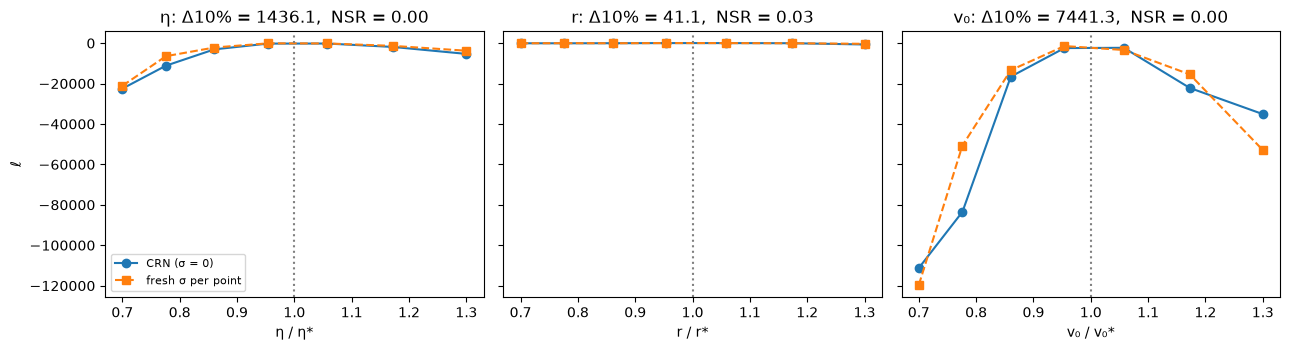

In [2]:
factors = np.exp(np.linspace(np.log(0.7), np.log(1.3), 7))
pts, fresh_seeds = [], []
for j in range(3):
    for i, f in enumerate(factors):
        th = TRUTH.copy()
        th[j] *= f
        pts.append(th)
        fresh_seeds.append(100 + 7 * j + i)
crn = A["slice_crn"]  # synlik_many(pts, s_obs, [0] * len(pts)).reshape(3, 7)
fresh = A["slice_fresh"]  # synlik_many(pts, s_obs, fresh_seeds).reshape(3, 7)
at_truth = A["ll_at_truth"]  # synlik_many([TRUTH] * 8, s_obs, list(range(200, 208)))
noise_sd = at_truth.std(ddof=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
u = np.log(factors)
for j, (ax, name) in enumerate(zip(axes, ("η", "r", "v₀"))):
    ax.plot(factors, crn[j], "o-", label="CRN (σ = 0)")
    ax.plot(factors, fresh[j], "s--", label="fresh σ per point")
    c = np.polyfit(u, crn[j], 2)[0]
    drop = -c * 0.1**2
    ax.set(
        xlabel=f"{name} / {name}*", title=f"{name}: Δ10% = {drop:.1f},  NSR = {noise_sd / drop:.2f}"
    )
    ax.axvline(1, c="gray", ls=":")
axes[0].set_ylabel("ℓ")
axes[0].legend(fontsize=8)
plt.tight_layout()
print(f"ℓ(θ*) over 8 fresh seeds: mean {at_truth.mean():.1f}, sd {noise_sd:.2f}")

**How to read this.** The panel titles give the drop Δ10% and the NSR for each parameter.
- **The noise of ℓ is about 1 unit** (sd over 8 seeds: 1.06).
- **A 10% change costs ~1400 units in η, ~40 in r and ~7400 in v₀.** The vertical axis spans −120 000.
  Blue and orange lie on top of each other; the noise is invisible at this scale.
- **NSR = 0.00, 0.03, 0.00:** the noise is irrelevant for finding the optimum. **Q1's answer:** the
  difficulty we were looking for (a noisy objective) does not appear.
- **Something else is visible:** the three parameters have wildly different curvatures. The likelihood is
  extremely narrow in v₀ and η and wide in r (the r panel looks flat at this scale). That matters for §2.

## 2. Q2 — multistart, waterfall, and where the starts went

**Method:**
- Run the optimiser (Nelder–Mead, a standard derivative-free method) from 8 starting points spread over
  the whole allowed box (a Latin hypercube).
- Each run gets at most 100 evaluations of ℓ, about 17 minutes of simulation each (loaded here from
  `results/`).

**How to read the two plots:**
- **Waterfall (left):** the final −ℓ of each run, sorted from best to worst. If all runs find the same
  optimum, the curve is **flat**: all points at the same height. The dotted line marks "best + 1".
- **Paths (right):** every point each optimiser evaluated, projected on the (η, r) plane (log axes). Open
  circles are starts, filled circles are ends, and the star is the truth.

**Pre-registered criterion:** one optimum if at least 6 of 8 runs end within 1 unit of the best.

starts within 1 unit of the best: 1 of 8  -> criterion NOT met
  start [0.531 1.876 0.019] -> θ̂ [2.0035 1.0141 0.03  ]  ℓ =    32.74  evals 100
  start [1.871 1.29  0.029] -> θ̂ [2.0407 1.0686 0.0302]  ℓ =    26.72  evals 100
  start [0.967 1.    0.05 ] -> θ̂ [2.3067 0.8072 0.0319]  ℓ =   -63.53  evals 100
  start [1.217 0.943 0.018] -> θ̂ [1.8012 0.639  0.029 ]  ℓ =   -81.02  evals 100
  start [4.069 0.559 0.024] -> θ̂ [2.2961 0.7562 0.0318]  ℓ =   -90.59  evals 100
  start [2.127 0.799 0.038] -> θ̂ [2.4753 0.9165 0.0324]  ℓ =   -98.57  evals 100
  start [0.727 0.628 0.059] -> θ̂ [1.6299 0.603  0.0285]  ℓ =  -172.50  evals 100
  start [3.329 1.607 0.035] -> θ̂ [3.2328 1.4433 0.0385]  ℓ =  -486.49  evals 100


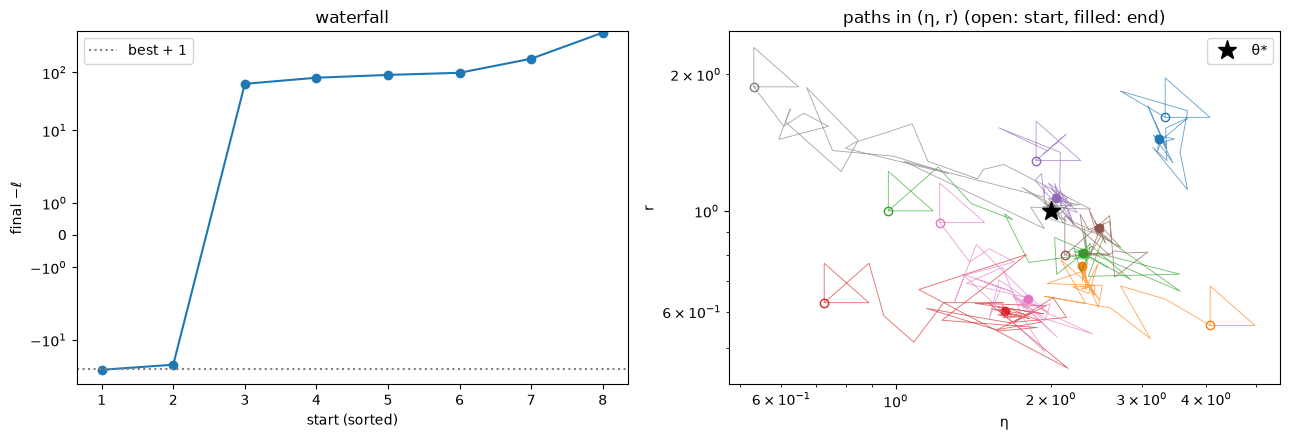

In [3]:
starts = latin_hypercube(8, np.random.default_rng(3))
fits = unpack_fits("multistart", A)  # fit_many(s_obs, list(starts), [0] * 8)
order = np.argsort([-f.loglik for f in fits])
best = fits[order[0]]

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5))
a.plot(range(1, 9), [-fits[i].loglik for i in order], "o-")
a.axhline(-best.loglik + 1, c="gray", ls=":", label="best + 1")
a.set(yscale="symlog", xlabel="start (sorted)", ylabel="final −ℓ", title="waterfall")
a.legend()
for i, f in enumerate(fits):
    path = np.array([p[0] for p in f.path])
    (line,) = b.plot(path[:, 0], path[:, 1], lw=0.6, alpha=0.7)
    b.plot(*f.start[:2], "o", c=line.get_color(), mfc="none")
    b.plot(*f.theta[:2], "o", c=line.get_color())
b.plot(*TRUTH[:2], "k*", ms=14, label="θ*")
b.set(
    xscale="log",
    yscale="log",
    xlabel="η",
    ylabel="r",
    title="paths in (η, r) (open: start, filled: end)",
)
b.legend()
plt.tight_layout()

within = sum(best.loglik - f.loglik <= 1 for f in fits)
print(
    f"starts within 1 unit of the best: {within} of 8  -> criterion {'MET' if within >= 6 else 'NOT met'}"
)
for i in order:
    f = fits[i]
    print(
        f"  start {f.start.round(3)} -> θ̂ {f.theta.round(4)}  ℓ = {f.loglik:8.2f}  evals {f.nfev}"
    )

In [4]:
print("best ℓ reached so far, after 50 / 75 / 100 evaluations:")
for f in fits:
    ll = np.array([p[1] for p in f.path])
    run = np.maximum.accumulate(np.where(np.isfinite(ll), ll, -1e9))
    print(f"  start {f.start.round(3)}: {run[49]:8.1f} {run[74]:8.1f} {run[-1]:8.1f}")

best ℓ reached so far, after 50 / 75 / 100 evaluations:
  start [3.329 1.607 0.035]:   -728.6   -486.5   -486.5
  start [4.069 0.559 0.024]:   -187.9    -99.1    -90.6
  start [0.967 1.    0.05 ]:    -69.5    -63.5    -40.3
  start [0.727 0.628 0.059]:   -205.9   -180.9   -172.5
  start [1.871 1.29  0.029]:     24.9     26.7     26.7
  start [2.127 0.799 0.038]:    -98.6    -98.6    -98.6
  start [1.217 0.943 0.018]:   -100.9    -81.0    -81.0
  start [0.531 1.876 0.019]:     24.1     32.2     32.7


**How to read this.**
- **The waterfall is not flat.** Only the best run (ℓ = 32.7) meets the criterion. The second (26.7) is close
  in θ but 6 units lower; the other six end between −64 and −486. **Criterion not met: 1 of 8.**
- **All 8 runs used their full 100 evaluations:** none declared convergence.
- **Paths:** the runs wander widely. Several end in a band where η and r have both increased or both
  decreased, e.g. (2.3, 0.81), (2.3, 0.76), (1.8, 0.64), (1.63, 0.60): displaced along a diagonal of the
  (η, r) plane.
- **The progress table:** some runs stopped improving long before the budget ran out (−98.6 from evaluation
  50 to 100), i.e. they are *stuck*. Others were still improving at 100 (−69.5 → −40.3 over the last 50),
  i.e. they *ran out of budget*.
- Is this several optima, or an optimiser that cannot reach the one optimum? §5 and §6 answer it.

## 3. Monte Carlo error of θ̂

The fit uses a particular set of random numbers (seed 0) for its simulations. How much would θ̂ change with
different random numbers? We restart the optimiser from the best point with seeds 1–4. The spread of the
five answers is the **Monte Carlo error**: the part of the uncertainty that comes from simulating, not from
the data. (The statistical uncertainty, how much θ̂ would change with *different data*, is notebook 05's job.)

In [5]:
mc = unpack_fits("mc", A)  # fit_many(s_obs, [best.theta] * 4, [1, 2, 3, 4])
th = np.array([best.theta] + [f.theta for f in mc])
print(f"{'σ':>3s} {'η̂':>8s} {'r̂':>8s} {'v̂₀':>8s} {'ℓ':>8s}")
for sd, f in zip([0, 1, 2, 3, 4], [best] + mc):
    print(f"{sd:3d} {f.theta[0]:8.4f} {f.theta[1]:8.4f} {f.theta[2]:8.5f} {f.loglik:8.2f}")
rel = th / TRUTH - 1
print(
    "\nrelative error vs θ*: mean",
    (100 * rel.mean(0)).round(2),
    "%   MC sd",
    (100 * rel.std(0, ddof=1)).round(2),
    "%",
)

  σ       η̂       r̂      v̂₀        ℓ
  0   2.0035   1.0141  0.03001    32.74
  1   2.0021   1.0074  0.02999    33.04
  2   2.0006   1.0032  0.02999    33.32
  3   2.0157   1.0244  0.03008    32.65
  4   2.0059   1.0183  0.03001    32.29

relative error vs θ*: mean [0.28 1.35 0.06] %   MC sd [0.3  0.84 0.12] %


**How to read this.**
- **All five fits land within ~2.5% of the truth**, and the mean errors are +0.3% (η), +1.4% (r) and +0.1% (v₀).
- **The Monte Carlo spread is small:** sd 0.3% (η), 0.8% (r), 0.1% (v₀). Simulation noise is not what limits
  the answer.
- **r is again the least precise**, by a factor of ~3, consistent with its wide likelihood in §1.
- The observed run was ~2 sd off in every summary (data table), yet the fit is on target: the deviation was
  a correlated fluctuation, and the covariance absorbed it.

## 4. Seeing it: the data, the fit, and a stalled fit

Three simulations with the same seed, coloured by cluster size:
- **left:** the truth θ*;
- **middle:** the best fit θ̂;
- **right:** where one of the stalled runs ended, (η, r, v₀) ≈ (2.31, 0.81, 0.032), with a much lower ℓ.

The bar is the unit of length; each panel's own parameters are in the line underneath.

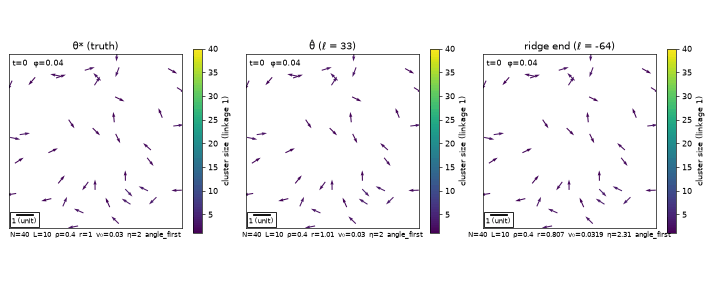

In [6]:
ridge = max((f for f in fits if best.loglik - f.loglik > 20), key=lambda f: f.loglik)
panels = [TRUTH, best.theta, ridge.theta]
trs = [simulate(params(t), 1500, seed=7, record_every=3) for t in panels]
gif = animate(
    trs,
    "truth_fit_ridge",
    color="cluster",
    gif=Path("../figures/truth_fit_ridge.gif"),
    stride=3,
    fps=15,
    dpi=60,
    titles=["θ* (truth)", f"θ̂ (ℓ = {best.loglik:.0f})", f"ridge end (ℓ = {ridge.loglik:.0f})"],
)
show(gif)

**How to read this.**
- **Left and middle** have practically the same parameters (θ̂ is within ~1.5% of θ*), so they are two
  realisations of the same flock. They differ in detail because θ̂ is not *exactly* θ*: the chaotic dynamics
  amplify any difference, whatever the seed. But they look statistically alike: mid-size teal groups plus
  scattered singles.
- **Right** (more noise, shorter radius, slightly faster) looks more fragmented: mostly small clusters.
  Even so, in single frames it is not dramatically different; the fit tells them apart through the
  *time-averaged* summaries, not snapshots.

## 5. Why do fits stall? ℓ on the (η, r) plane

A picture for interpretation, not part of the protocol: ℓ on an 11 × 11 grid of (η, r), log-spaced, with v₀
fixed at the true 0.03, using the fixed random numbers of the fit. This costs 121 evaluations; notebook 04 does the
same analysis properly.

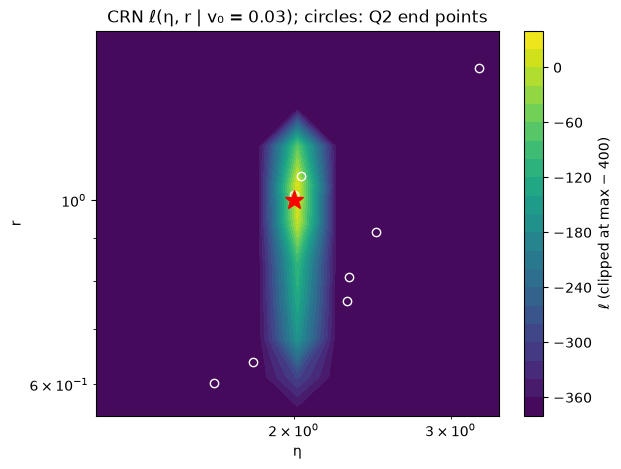

In [7]:
G_ETA = np.exp(np.linspace(np.log(1.2), np.log(3.4), 11))
G_R = np.exp(np.linspace(np.log(0.55), np.log(1.6), 11))
grid = [np.array([e, r, 0.03]) for r in G_R for e in G_ETA]
Z = A["grid_ll"]  # synlik_many(grid, s_obs, [0] * len(grid)).reshape(len(G_R), len(G_ETA))
fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contourf(G_ETA, G_R, np.maximum(Z, Z.max() - 400), levels=20, cmap="viridis")
fig.colorbar(cs, label="ℓ (clipped at max − 400)")
for f in fits:
    ax.plot(*f.theta[:2], "wo", mfc="none")
ax.plot(*TRUTH[:2], "r*", ms=14)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="η",
    ylabel="r",
    title="CRN ℓ(η, r | v₀ = 0.03); circles: Q2 end points",
);

**How to read this.**
- **Colour is ℓ**, clipped at 400 below the maximum; the red star is the truth.
- **The high region is a thin vertical band**: narrow in η (a few percent) and much longer in r. Far from
  it, ℓ drops by hundreds of units.
- **The white circles are where the 8 runs ended**, projected on this plane. Their own v₀ is not 0.03, and ℓ
  is very steep in v₀, so they are worse than the colour under them suggests. Most lie *outside* the band.
- **A reading of the stall:** the optimiser's first steps are ±20% in each parameter, far wider than the band.
  A run that starts off the band keeps stepping over it and never finds it. (The η–v₀ side of the problem,
  a curved valley, is diagnosed in the second attempt below.)

## 6. Exploratory (not pre-registered): restart from each end point

The standard remedy for a Nelder–Mead run that has collapsed is to **restart** it from where it stopped,
with a fresh starting simplex (same settings, another 100 evaluations). If the runs were merely slow, this
should bring them to the optimum.

In [8]:
restart = unpack_fits("restart", A)  # fit_many(s_obs, [f.theta for f in fits], [0] * 8)
for f, g in zip(fits, restart):
    print(f"  {f.theta.round(4)} ℓ={f.loglik:8.2f}  ->  {g.theta.round(4)} ℓ={g.loglik:8.2f}")
all_ll = np.array([g.loglik for g in restart])
print(f"after restart, within 1 unit of the best: {(all_ll.max() - all_ll <= 1).sum()} of 8")

  [3.2328 1.4433 0.0385] ℓ= -486.49  ->  [3.2328 1.4433 0.0385] ℓ= -486.49
  [2.2961 0.7562 0.0318] ℓ=  -90.59  ->  [2.2818 0.9169 0.0317] ℓ=  -37.32
  [2.3067 0.8072 0.0319] ℓ=  -63.53  ->  [2.3022 0.8017 0.0318] ℓ=  -44.56
  [1.6299 0.603  0.0285] ℓ= -172.50  ->  [1.7547 0.6174 0.0287] ℓ= -161.56
  [2.0407 1.0686 0.0302] ℓ=   26.72  ->  [2.0505 1.0247 0.0302] ℓ=   32.11
  [2.4753 0.9165 0.0324] ℓ=  -98.57  ->  [2.456  0.9627 0.0327] ℓ=  -77.71
  [1.8012 0.639  0.029 ] ℓ=  -81.02  ->  [1.8012 0.639  0.029 ] ℓ=  -81.02
  [2.0035 1.0141 0.03  ] ℓ=   32.74  ->  [2.0042 1.014  0.03  ] ℓ=   32.80
after restart, within 1 unit of the best: 2 of 8


**How to read this.** Each line is one run: where it had ended → where the restart ended.
- **Only one more run reaches the top** (26.7 → 32.1). Criterion after restart: **2 of 8**.
- **Two runs do not move at all** (−486.49 and −81.02, identical before and after). From those points, every
  trial step of ±20% is worse, so the simplex shrinks in place.
- Others improve a little (for example −90.6 → −37.3) but stay far below.
- **What this shows:** what governs the search is the *shape* of the likelihood (narrow, badly scaled), not
  just the budget.

## 7. What this taught us

**The point estimate works when the optimiser finds the peak.**
- The best start gives $\hat\theta = (2.004, 1.014, 0.0300)$, against $\theta^* = (2, 1, 0.03)$.
- Averaged over the 5 CRN seeds, the relative errors are +0.3% (η), +1.4% (r) and +0.1% (v₀).
- The Monte Carlo spread over seeds is 0.3%, 0.8% and 0.1%.
- r is the least precise parameter by a factor of about 3.
- The observed run happens to lie ~2 sd from μ̂(θ*) in *every* summary, yet $\hat\theta$ is on target: the
  deviation follows the correlation structure of $\hat\Sigma$ (a fluctuation, not a parameter change).

**Q1: the noisy objective is not the difficulty** (the question we fixed in advance).
- The spread of $\ell_\sigma(\theta^*)$ over seeds is about 1 unit.
- A 10% change drops ℓ by ~1400 (η), ~40 (r) and ~7400 (v₀), so NSR ≤ 0.03.
- CRN and fresh-seed slices are indistinguishable at this scale.

**Q2: one optimum, hard to reach.** The pre-registered criterion is not met (1 of 8 starts; 2 of 8 after the
exploratory restart), and the cause is identified: **conditioning**, not several optima, and not noise.
- The synthetic likelihood is extremely peaked: a valley a few % wide in v₀ and η, and much wider in r.
  Curvatures differ by a factor of ~180.
- An initial simplex of ±20% in log steps over the valley. Starts that land off it cannot find it: two
  did not move at all, even when restarted with a fresh simplex.
- The difficulty SIR never showed did appear, but it is ill-conditioning. That is an ordinary numerical
  problem, not a statistical one.

**Correction to the notebook 01 expectation.** notebook 01 saw an η–r ridge (z_η/z_r ≈ −1) in φ, χ and the correlations.
With `speed` and `cos_turn` in the vector, η is pinned, and the weak direction is **r alone**: the valley in
§5 is vertical, not diagonal. Whether r is *identifiable*, and how well, is exactly notebook 04's question.

**Stopping criterion.** If a single best-fit θ is all you need: yes, but only with a start inside the
valley. As pre-registered, the answer is "not established", because the waterfall does not show one optimum.

**What would fix the optimisation** (not done here; a candidate for a second attempt, fixed in advance):
- Start from moment estimates: v₀ from `speed` (notebook 01 showed it pins v₀), and η from `cos_turn`. That is the
  ladder working as intended: a cheap rung gives the starting point for the next.
- Or scale the simplex by the curvatures found in Q1, or use a method that adapts its step (CMA-ES).

**Cost.**
- ~10 s per evaluation (B = 40 replicas × 10 000 steps, observables included), after the numba kernel.
- The 8-start multistart took ~40 min on 6 processes; the Monte Carlo re-fits another ~18 min.
- Here everything is loaded from `results/`; `scripts/a3_point_fit.py` regenerates it.

## 8. A second attempt — the same question, with remedies (fixed before running)

**Why a second attempt?** The first attempt located the difficulty: scaling. We used that diagnosis and wrote
down three remedies *before running them*, to test whether they fix it. The
question "are there too many summaries?" led to the first one: the redundancy of the
summaries makes the covariance nearly singular, and with only 40 runs its small eigenvalues are
underestimated.

The data, summaries, box, budget and criterion are unchanged. The three remedies:

**Shrunk covariance** (Schäfer & Strimmer 2005; `flockladder.synlik.shrunk_cov`). With standardized columns
$z_{bi} = (s_{bi}-\bar s_i)/\hat\sigma_i$ and $w_{bij} = z_{bi} z_{bj}$:

$$\hat r_{ij} = \frac{1}{B-1}\sum_b w_{bij}, \qquad
\widehat{\mathrm{Var}}(\hat r_{ij}) = \frac{B}{(B-1)^3}\sum_b (w_{bij}-\bar w_{ij})^2, \qquad
\lambda^* = \min\!\Big(1, \frac{\sum_{i\ne j}\widehat{\mathrm{Var}}(\hat r_{ij})}{\sum_{i\ne j}\hat r_{ij}^2}\Big)$$

$$\hat\Sigma^*_{ij} = \hat\sigma_i\hat\sigma_j\,\big[(1-\lambda^*)\,\hat r_{ij}\big]_{i\ne j}, \qquad \hat\Sigma^*_{ii} = \hat\sigma_i^2$$

**Pilot** (Fearnhead & Prangle 2012; `flockladder.synlik.pilot`).
- $M = 100$ values $\theta_m$ from a Latin hypercube in the box, one run each.
- Least squares $\log\theta_m \approx \beta_0 + \beta^\top \tilde{\mathbf s}_m$, with $\tilde{\mathbf s}$ the standardized summaries.
- $\tilde\theta = \exp(\beta_0 + \beta^\top\tilde{\mathbf s}_{\rm obs})$. $\rho_j$ = the residual sd of $\log\theta_j$.

**Scaled simplex:** $x_0 + \rho_j\,\mathbf e_j$.

**Arms:**
- **A:** the notebook 03 starts (whole box).
- **B:** 8 Latin-hypercube starts in $\log\tilde\theta \pm 2\rho$.

Both use the shrunk Σ and the scaled simplex.

In [9]:
from flockladder.synlik import shrunk_cov


# how shrinkage changes the Q1 curvatures (the same simulations as the slices of §1)
def ll_from(S, shrink):
    mu = S.mean(0)
    C = shrunk_cov(S)[0] if shrink else np.cov(S, rowvar=False)
    d = s_obs - mu
    return -0.5 * d @ np.linalg.solve(C, d) - 0.5 * np.linalg.slogdet(C)[1]


SL = A["slice_summaries"]  # summary_matrix(th, 40, 0) at the 21 slice points of §1
for shrink in (False, True):
    drops = []
    for j in range(3):
        vals = [ll_from(SL[7 * j + i], shrink) for i in range(7)]
        drops.append(-np.polyfit(u, vals, 2)[0] * 0.01)
    print(
        f"{'shrunk' if shrink else 'plain '} Σ: Δ10% η, r, v₀ = {np.round(drops, 1)}   max/min = {max(drops) / min(drops):.0f}"
    )
print(f"λ* at θ* = {shrunk_cov(S)[1]:.3f}")

# pilot(): 100 single runs on a Latin hypercube, then a linear regression of log θ on the summaries
th_tilde, resid_sd = A["pilot_theta"], A["pilot_resid_sd"]
print(f"\npilot: θ̃ = {th_tilde.round(4)}  (θ* = {TRUTH})   ρ = {resid_sd.round(3)}")

plain  Σ: Δ10% η, r, v₀ = [1436.1   41.1 7441.3]   max/min = 181
shrunk Σ: Δ10% η, r, v₀ = [ 672.9   24.6 4098.3]   max/min = 167
λ* at θ* = 0.060

pilot: θ̃ = [2.4665 1.0767 0.0301]  (θ* = [2.   1.   0.03])   ρ = [0.186 0.142 0.116]


**How to read this.**
- **Shrinkage** pulls the estimated correlations between summaries slightly towards zero. The automatically
  chosen amount is λ* = 0.06, i.e. 6%.
- It **halves** every curvature (η: 1436 → 673, r: 41 → 25, v₀: 7441 → 4098). This is the artefact of
  estimating Σ from only 40 runs, now removed.
- But the **ratio** between the sharpest and the widest direction barely changes (181 → 167). The bad
  scaling is a real property of the problem, not an artefact.
- **The pilot estimate** θ̃ = (2.47, 1.08, 0.0301) comes from a quick linear regression on 100 cheap
  simulations. It is rough: η is 23% high. But it is close enough to be a sensible *starting region*, and
  its residual spreads ρ (0.19, 0.14, 0.12 in log) give natural step sizes for the optimiser.

A (box starts): within 1 unit of its best: 2 of 8 -> criterion NOT met; all hit maxfev: True
   [1.871 1.29  0.029] -> [2.0162 1.0125 0.0301]  ℓ =    32.07
   [2.127 0.799 0.038] -> [2.0145 1.0002 0.03  ]  ℓ =    32.02
   [0.531 1.876 0.019] -> [1.932  0.798  0.0297]  ℓ =    -3.95
   [4.069 0.559 0.024] -> [2.0515 0.7236 0.0303]  ℓ =   -19.66
   [0.727 0.628 0.059] -> [2.2609 0.7491 0.0317]  ℓ =   -62.04
   [1.217 0.943 0.018] -> [1.5619 0.598  0.0281]  ℓ =   -96.63
   [0.967 1.    0.05 ] -> [1.8106 1.1714 0.029 ]  ℓ =  -100.44
   [3.329 1.607 0.035] -> [3.386  1.4503 0.0404]  ℓ =  -427.15
B (pilot starts): within 1 unit of its best: 2 of 8 -> criterion NOT met; all hit maxfev: True
   [1.942 0.868 0.028] -> [2.0245 1.0039 0.0301]  ℓ =    32.15
   [2.668 0.894 0.035] -> [2.0001 0.9981 0.03  ]  ℓ =    31.81
   [1.77  1.173 0.031] -> [2.1175 1.0447 0.0306]  ℓ =    28.10
   [2.18  1.007 0.029] -> [2.1049 1.0758 0.0305]  ℓ =    27.08
   [3.475 1.145 0.026] -> [2.3186 1.1112 0.0318]  ℓ =   

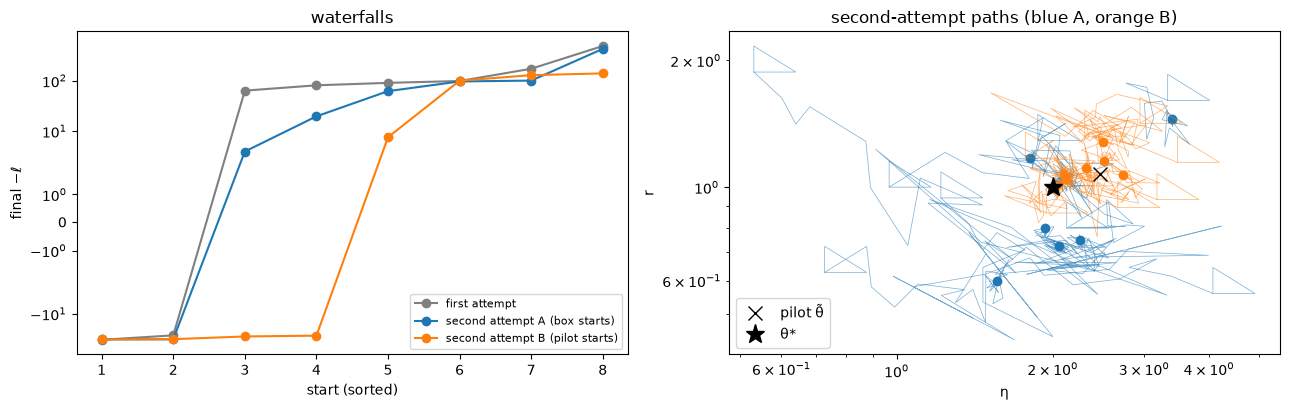

In [10]:
region = np.clip(
    np.stack([th_tilde * np.exp(-2 * resid_sd), th_tilde * np.exp(2 * resid_sd)], 1),
    BOX[:, :1],
    BOX[:, 1:],
)
starts_A = latin_hypercube(8, np.random.default_rng(3))
starts_B = latin_hypercube(8, np.random.default_rng(5), box=region)
# fit_many(s_obs, list(starts_A) + list(starts_B), [0] * 16, step=resid_sd, shrink=True)
arms = {"A (box starts)": unpack_fits("arm_a", A), "B (pilot starts)": unpack_fits("arm_b", A)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(range(1, 9), sorted(-f.loglik for f in fits), "o-", c="gray", label="first attempt")
for name, fs in arms.items():
    ax.plot(range(1, 9), sorted(-f.loglik for f in fs), "o-", label=f"second attempt {name}")
ax.set(yscale="symlog", xlabel="start (sorted)", ylabel="final −ℓ", title="waterfalls")
ax.legend(fontsize=8)
ax = axes[1]
for name, fs in arms.items():
    for f in fs:
        path = np.array([p[0] for p in f.path])
        ax.plot(path[:, 0], path[:, 1], lw=0.5, alpha=0.6, c="C0" if name.startswith("A") else "C1")
        ax.plot(*f.theta[:2], "o", c="C0" if name.startswith("A") else "C1")
ax.plot(*th_tilde[:2], "kx", ms=10, label="pilot θ̃")
ax.plot(*TRUTH[:2], "k*", ms=14, label="θ*")
ax.set(
    xscale="log",
    yscale="log",
    xlabel="η",
    ylabel="r",
    title="second-attempt paths (blue A, orange B)",
)
ax.legend()
plt.tight_layout()

for name, fs in arms.items():
    best_ll = max(f.loglik for f in fs)
    n1 = sum(best_ll - f.loglik <= 1 for f in fs)
    print(
        f"{name}: within 1 unit of its best: {n1} of 8 -> criterion {'MET' if n1 >= 6 else 'NOT met'};"
        f" all hit maxfev: {all(f.nfev >= 100 for f in fs)}"
    )
    for f in sorted(fs, key=lambda f: -f.loglik):
        print(f"   {f.start.round(3)} -> {f.theta.round(4)}  ℓ = {f.loglik:8.2f}")

**How to read this.**
- **Waterfalls (left):**
  - grey is notebook 03;
  - blue is arm A: the same box starts, with shrinkage and scaled steps;
  - orange is arm B: starts near the pilot estimate.

  Arm B puts 4 runs near the top against 2, but no curve is flat.
- **Criterion:** 2 of 8 in each arm. Not met. Every run again used all 100 evaluations.
- **Paths (right):** the orange runs stay near the pilot (×) and the truth (★); the blue ones still wander
  over the whole box.
- **The runs that stall have a pattern:**
  - they end where η and v₀ have *both* increased, e.g. (2.32, 1.11, 0.0318) and (2.51, 1.16, 0.0335);
  - at those points the observed `speed` is matched, but cos_turn and corr_0_1 are 8–9 sd off (checked
    separately; see the LOG).
- **That is the key diagnosis.** There is a thin, *curved* valley along which the apparent speed stays
  constant: more noise shortens the net displacement, and a faster v₀ compensates. Nelder–Mead crawls
  along it.

## 9. What the second attempt taught us

**The second attempt explains the stall.** On uniqueness, the pre-registered criterion is not met in either
arm (2 of 8 each; every fit hit maxfev = 100), so the answer stays "not established". What it does establish
is why fits stall:

**What the remedies did:**
- **Shrinkage** (λ* ≈ 0.06): it halves the curvatures (Δ10% η, r, v₀: 1436 → 673, 41 → 25, 7441 → 4098),
  which is the B = 40 artefact removed. But the *ratio* barely moves (181 → 167), so the conditioning is
  intrinsic.
- **Pilot and scaled simplex:** the pilot θ̃ = (2.47, 1.08, 0.0301) is rough (η +23%). Starting near it (arm B)
  brings 4 of 8 fits within 5 units of the best, against 2 of 8 from box starts (arm A) and 2 of 8 in notebook 03.
  The waterfalls improve but do not flatten.

**Why it stalls: a narrow curved valley along constant `speed`.** At the stalled end points, `speed` often
matches the data while `cos_turn` and `corr_0_1` are 8–9 sd off; the end points where η and v₀ rose
together, (2.12, 0.031) and (2.51, 0.034), show it most clearly.
- Along the valley, more noise shortens the net displacement and a larger v₀ compensates. That is the
  v₀–η confusion of notebook 01.
- It does **not** make the parameters unidentifiable (the peak is unique and sharp). It makes the peak
  **hard to reach**: a thin curved valley that Nelder–Mead crawls along.
- Notebook 01 called the confusion "harmless": that holds for identifiability, while for optimisation it is
  what shapes the search.

**No competing optimum was found.** Across 32 fits (the first attempt, the second attempt and the restart), every end point with ℓ > 0 lies
within ~8% of θ*. The ones that reach the top agree to ≤ 1.5% (see §3 for the Monte Carlo spread).

**Stopping criterion, practically:** a best-of-multistart estimate is reliable. With ≥ 8 starts, at
least 2 found the same θ̂ in every batch. Proving "one optimum" with Nelder–Mead at 100 evaluations was not
achieved, and more of the same would only buy compute.

**For later rungs:** the same curved valley will slow any sampler in [notebook 06](06_posterior.ipynb) (MCMC). The natural
remedy is to **reparametrize along it**, e.g. (η, r, w) with w the apparent speed at θ instead of v₀. Record
this and decide there; it is not done here.

**Cost:** the second attempt took ~76 min on 6 processes (16 fits × 100 evaluations); the pilot took 11 s.